# 2. Nested cross-validation

Outer loop: 5 stratified folds, 6 test samples each. Inside every outer fold the DEG filter and the full
genetic algorithm run only on the 24 training samples (inner fitness: 4-fold CV). The test fold never
touches gene selection. Baselines use the same per-fold DEG pool.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load, symbols, name, RESULTS
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY, RED = "#184E7D", "#B8B8B8", "#A4243B"
FIG = RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

expr, y, meta = load()
sym = symbols()

In [2]:
from src.validation import cached, nested_ga, nested_baselines, rf_baseline

ga = cached("nested_ga_seed42", lambda: nested_ga(expr, y, seed=42))
pd.DataFrame(ga).assign(selected=lambda d: d.genes.str.len()).drop(columns="genes").round(3)

,fold,auc,pool,selected
0,1,0.500,227,12
1,2,1.000,118,7
2,3,1.000,93,5
3,4,1.000,127,12
4,5,0.889,111,8


The run reported in the thesis (AUC 0.919 ± 0.068) was not seeded, so it cannot be reproduced exactly.
With only 6 test samples per fold, one different GA decision can move a fold AUC by 0.3-0.5, so a single
run is a noisy estimate. Below, the whole nested procedure is repeated with six GA seeds on the same outer folds.

In [3]:
from src.validation import repeated_nested_ga

seeds = [42, 0, 1, 2, 3, 4]
reps = pd.DataFrame(repeated_nested_ga(expr, y, seeds), index=[f"fold {i}" for i in range(1, 6)]).T
reps["mean"] = reps.mean(axis=1)
print(f"mean AUC over {len(seeds)} seeds: {reps['mean'].mean():.3f}  "
      f"(per-seed range {reps['mean'].min():.3f}-{reps['mean'].max():.3f})")
reps.rename_axis("GA seed").round(3)

mean AUC over 6 seeds: 0.834  (per-seed range 0.725-0.903)


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
GA seed,,,,,,
42,0.500,1.000,1.0,1.000,0.889,0.878
0,0.625,0.889,1.0,1.000,1.000,0.903
1,0.875,0.667,1.0,0.722,0.889,0.831
2,0.125,0.889,1.0,0.722,0.889,0.725
3,0.750,0.722,1.0,0.778,1.000,0.850
4,0.750,0.778,1.0,0.667,0.889,0.817


In [4]:
no_known = cached("nested_ga_no_known", lambda: nested_ga(expr, y, known=False))
auc = [f["auc"] for f in no_known]
print(f"without the 4 literature genes: AUC = {np.mean(auc):.3f} ± {np.std(auc):.3f}")

without the 4 literature genes: AUC = 0.908 ± 0.084


In [5]:
base = cached("baselines", lambda: nested_baselines(expr, y))
rf = cached("rf_baseline", lambda: rf_baseline(expr, y))

import json
folds = reps.drop(columns="mean").to_numpy()
sizes = [len(f["genes"]) for s in seeds for f in json.loads((RESULTS / f"nested_ga_seed{s}.json").read_text())]
rows = [("Genetic algorithm (6 seeds)", folds.ravel(), sizes),
        ("Random Forest (top-124 F-test)", rf, [124] * 5)]
rows += [(k, [f["auc"] for f in v], [f["features"] for f in v]) for k, v in base.items()]
summary = pd.DataFrame([{"method": m, "AUC mean": np.mean(a), "AUC std": np.std(a),
                         "features": f"{min(n)}-{max(n)}"} for m, a, n in rows]).set_index("method")
summary.round(3)

,AUC mean,AUC std,features
method,,,
Genetic algorithm (6 seeds),0.834,0.191,4-19
Random Forest (top-124 F-test),0.878,0.194,124-124
LASSO (L1),0.656,0.286,9-16
Ridge (L2),0.811,0.171,93-227
Elastic-net,0.744,0.191,43-134


GA row: mean and std over all 30 fold AUCs (6 seeds x 5 folds). Other rows: 5 folds, deterministic.

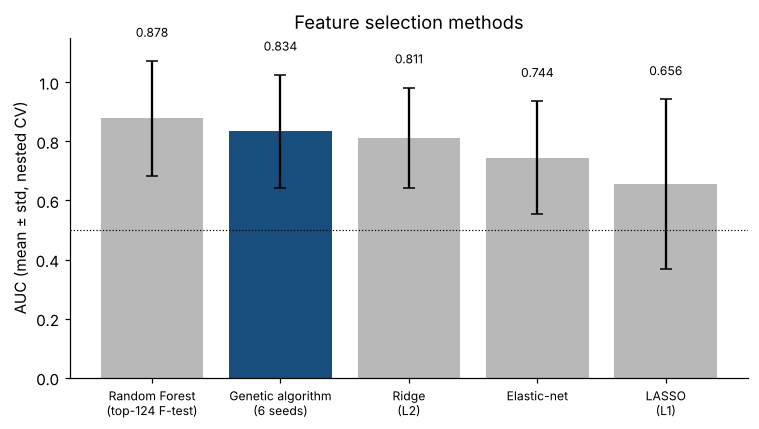

In [6]:
s = summary.sort_values("AUC mean", ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
labels = s.index.str.replace(" (", "\n(", regex=False)
bars = ax.bar(labels, s["AUC mean"],
              yerr=s["AUC std"], capsize=4, color=[BLUE if "Genetic" in m else GRAY for m in s.index])
ax.bar_label(bars, fmt="%.3f", padding=14, fontsize=8)
ax.axhline(0.5, ls=":", c="k", lw=0.8)
ax.set(ylabel="AUC (mean ± std, nested CV)", ylim=(0, 1.15), title="Feature selection methods")
plt.xticks(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "method_comparison.png", dpi=200)